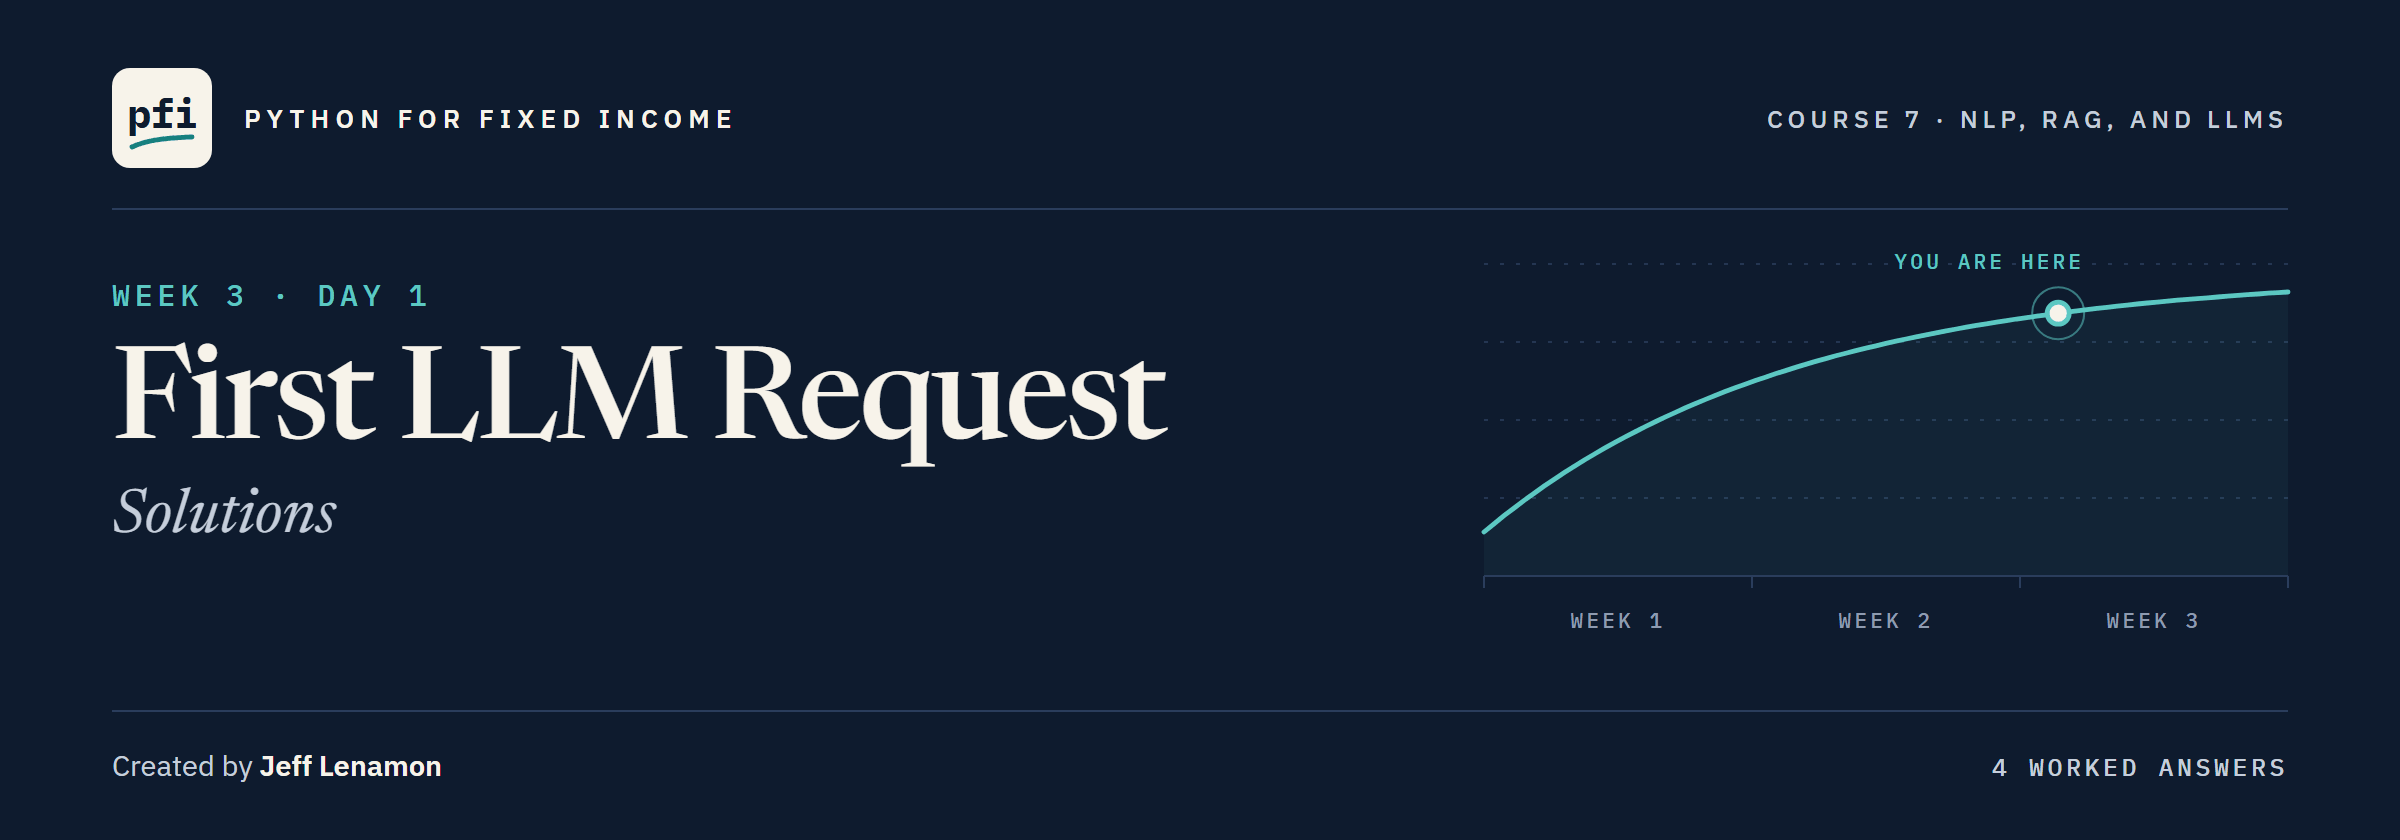

# First LLM Request: Solutions

Week 3, Day 1. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day1/11_first_llm_call_solutions.ipynb)

# Problem Statement

## Business Context

A credit desk wants to ask a language model what its documents say, and to use an answer only after code that never touched the model has checked it against the text.
Today's documents are the FOMC statement of 2026-09-16 and one paragraph of the Boyd indenture, both public.
The desk needs to know what one request holds, what it costs, why the same question can come back in other words, and how a notebook runs with no key.
Every response today was sent by the course on 2026-10-08 and saved, and the notebook replays it.
A response is text the model returned about what a document says, never a view on the Committee or the issuer.

## Objectives

Write a request as a system prompt, a user message and its settings.
Load a key without showing it, and replay saved responses without one.
Check a number in a response against the document with code.
Read what comes back, and price a request in tokens.
Set temperature, seed, `max_tokens` and reasoning, and say what each changes.
Read an HTTP refusal, and move a request to another route.

## Data Dictionary

`course7_fomc_statements.csv`: Day 1's file; today the statement of 2026-09-16.

`course7_indentures/boyd_2021.txt`: Day 1's indenture; today paragraph (b) of Section 3.07.

`course7_llm_responses/day11/<key>.json`, one saved response a file:

1. `request`: what was sent: `provider`, `model`, `messages` and `params`
2. `content`: the text the model returned
3. `model`: the model that answered, as its provider names it
4. `provider`: the company that ran the model
5. `usage`: what was counted and billed: `prompt_tokens`, `completion_tokens`, `total_tokens`, `completion_tokens_details`, `cost`
6. `finish_reason`: why the model stopped
7. `recorded`: the date the response was saved

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text, fingerprints, captured printing and a small stand-in object
import contextlib
import hashlib
import io
import json
import re
import sys
import unicodedata
from types import SimpleNamespace

# data, charts and the slider
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the client for a language model, and Course 3's reader of a .env file
import openai
from dotenv import dotenv_values

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

Day 1's `data_file`: the repo's path on your machine, a copy downloaded once in Colab.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

## Day 1's Text Tools

Day 1 wrote these; they are repeated here as one cell.

In [4]:
# Day 1's look-alike map, normalize_text, tokens and the two source lines
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def tokenize(text):
    """The course's tokens of a text, in lower case, after normalize_text."""
    return re.findall(TOKEN_PATTERN, normalize_text(text).lower())


def statement_source(row):
    """Print the source line of one statement."""
    print(f"Source: FOMC post-meeting statement of {row['date']}, Board of Governors of the Federal Reserve System, {row['url']}")


def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")

# Loading the Data

## The Statement of 2026-09-16

In [5]:
# source text: quoted as published
# the statement of 2026-09-16 through normalize_text: its size, then its first 300 characters
statements = pd.read_csv(DATA + "course7_fomc_statements.csv")
row = statements[statements["date"] == "2026-09-16"].iloc[0]
statement = normalize_text(row["text"])
print(len(statement), "characters in", statement.count("\n") + 1, "paragraphs")
print(statement[:300])
statement_source(row)

843 characters in 4 paragraphs
The Federal Open Market Committee approved the following statement for release by a 12 - 0 vote:
The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate. The Committee is continuing its
Source: FOMC post-meeting statement of 2026-09-16, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/newsevents/pressreleases/monetary20260916a.htm


The whole statement is 843 characters in 4 paragraphs, and the vote line's en dash prints as a hyphen.

## One Paragraph of the Indenture

`text.index(words, start)` returns where `words` first appear at or after `start`.

In [6]:
# source text: quoted as published
# paragraph (b) of Section 3.07: the first line that starts this way after the body's heading (Day 1's last heading)
boyd = normalize_text(Path(data_file("course7_indentures/boyd_2021.txt")).read_text(encoding="utf-8"))
heading = [found.start() for found in re.finditer(r"^Section 3\.07\. ", boyd, flags=re.MULTILINE)][-1]
start = boyd.index("(b) At any time prior to June 15, 2024", heading)
paragraph = boyd[start:boyd.index("\n", start)]
print(len(paragraph), "characters,", len(paragraph.split()), "words")
print(paragraph)
boyd_source("3.07")

513 characters, 91 words
(b) At any time prior to June 15, 2024, the Company may on any one or more occasions redeem up to 40% of the aggregate principal amount of Notes at a redemption price of 104.750% of the principal amount thereof with the Net Cash Proceeds of one or more Equity Offerings, plus accrued and unpaid interest and Additional Interest, if any, to the redemption date, subject to the rights of Holders of such Notes on any relevant record date to receive interest due on the relevant interest payment date; provided that:
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 3.07.


The paragraph holds two percentages, 40% and 104.750%, and no interest rate.

**Two short public texts, each with its source line: everything the model is sent today.**

# Writing a Request

A **large language model (LLM)** writes text that continues the text it is given.
A **request** is a small document we write for it: a list of **messages**, each with a **role**, and a few **settings**.
What comes back is the **response**.

## The System Prompt

The **system prompt** is the first message, role `system`: the rules every request repeats.
The course's is fixed, word for word the text its responses were recorded with.

In [7]:
# the instruction sent first in every request of the course
SYSTEM_PROMPT = (
    "You extract information from the document text in the user message. Quote the text exactly, character for "
    "character, and give the number of the section each quote comes from. Write every number exactly as the text "
    "writes it. If the text does not answer the question, reply NOT IN TEXT. If the user asks for an opinion, a "
    "grade, a comparison of quality, an ordering of securities or issuers, advice about trading, or a view about "
    "the future, reply exactly: REFUSED: this course asks only what the document says"
)
print(len(SYSTEM_PROMPT), "characters,", len(SYSTEM_PROMPT.split()), "words")

509 characters, 89 words


Four rules: quote exactly with the section number, write numbers as the text does, reply NOT IN TEXT when the text is silent, and reply REFUSED to anything but what the document says.

## The User Message

The **user message**, role `user`, holds the question, a blank line, a label line ending with a colon, then the document.
The label line marks where the document starts.

In [8]:
# the question, a blank line, the label line, then the normalised statement
QUESTION = "What does this statement say about the target range for the federal funds rate?"
user_message = f"{QUESTION}\n\nFOMC statement of {row['date']}:\n{statement}"
print(len(QUESTION), "characters of question |", len(user_message), "characters in the message")
print(user_message[:150])

79 characters of question | 954 characters in the message
What does this statement say about the target range for the federal funds rate?

FOMC statement of 2026-09-16:
The Federal Open Market Committee appro


## The Settings

A model is named by its **id**; this one ends `:free`.

In [9]:
# the model, and the five settings every request of the course writes out
TEXT_MODEL = "nvidia/nemotron-3-super-120b-a12b:free"
NO_REASONING = {"reasoning": {"enabled": False}}
params = {"temperature": 0.0, "seed": SEED, "max_tokens": 2000, "response_format": None, "extra_body": NO_REASONING}
for name, value in params.items():
    print(f"{name:16}{value}")

temperature     0.0
seed            42
max_tokens      2000
response_format None
extra_body      {'reasoning': {'enabled': False}}


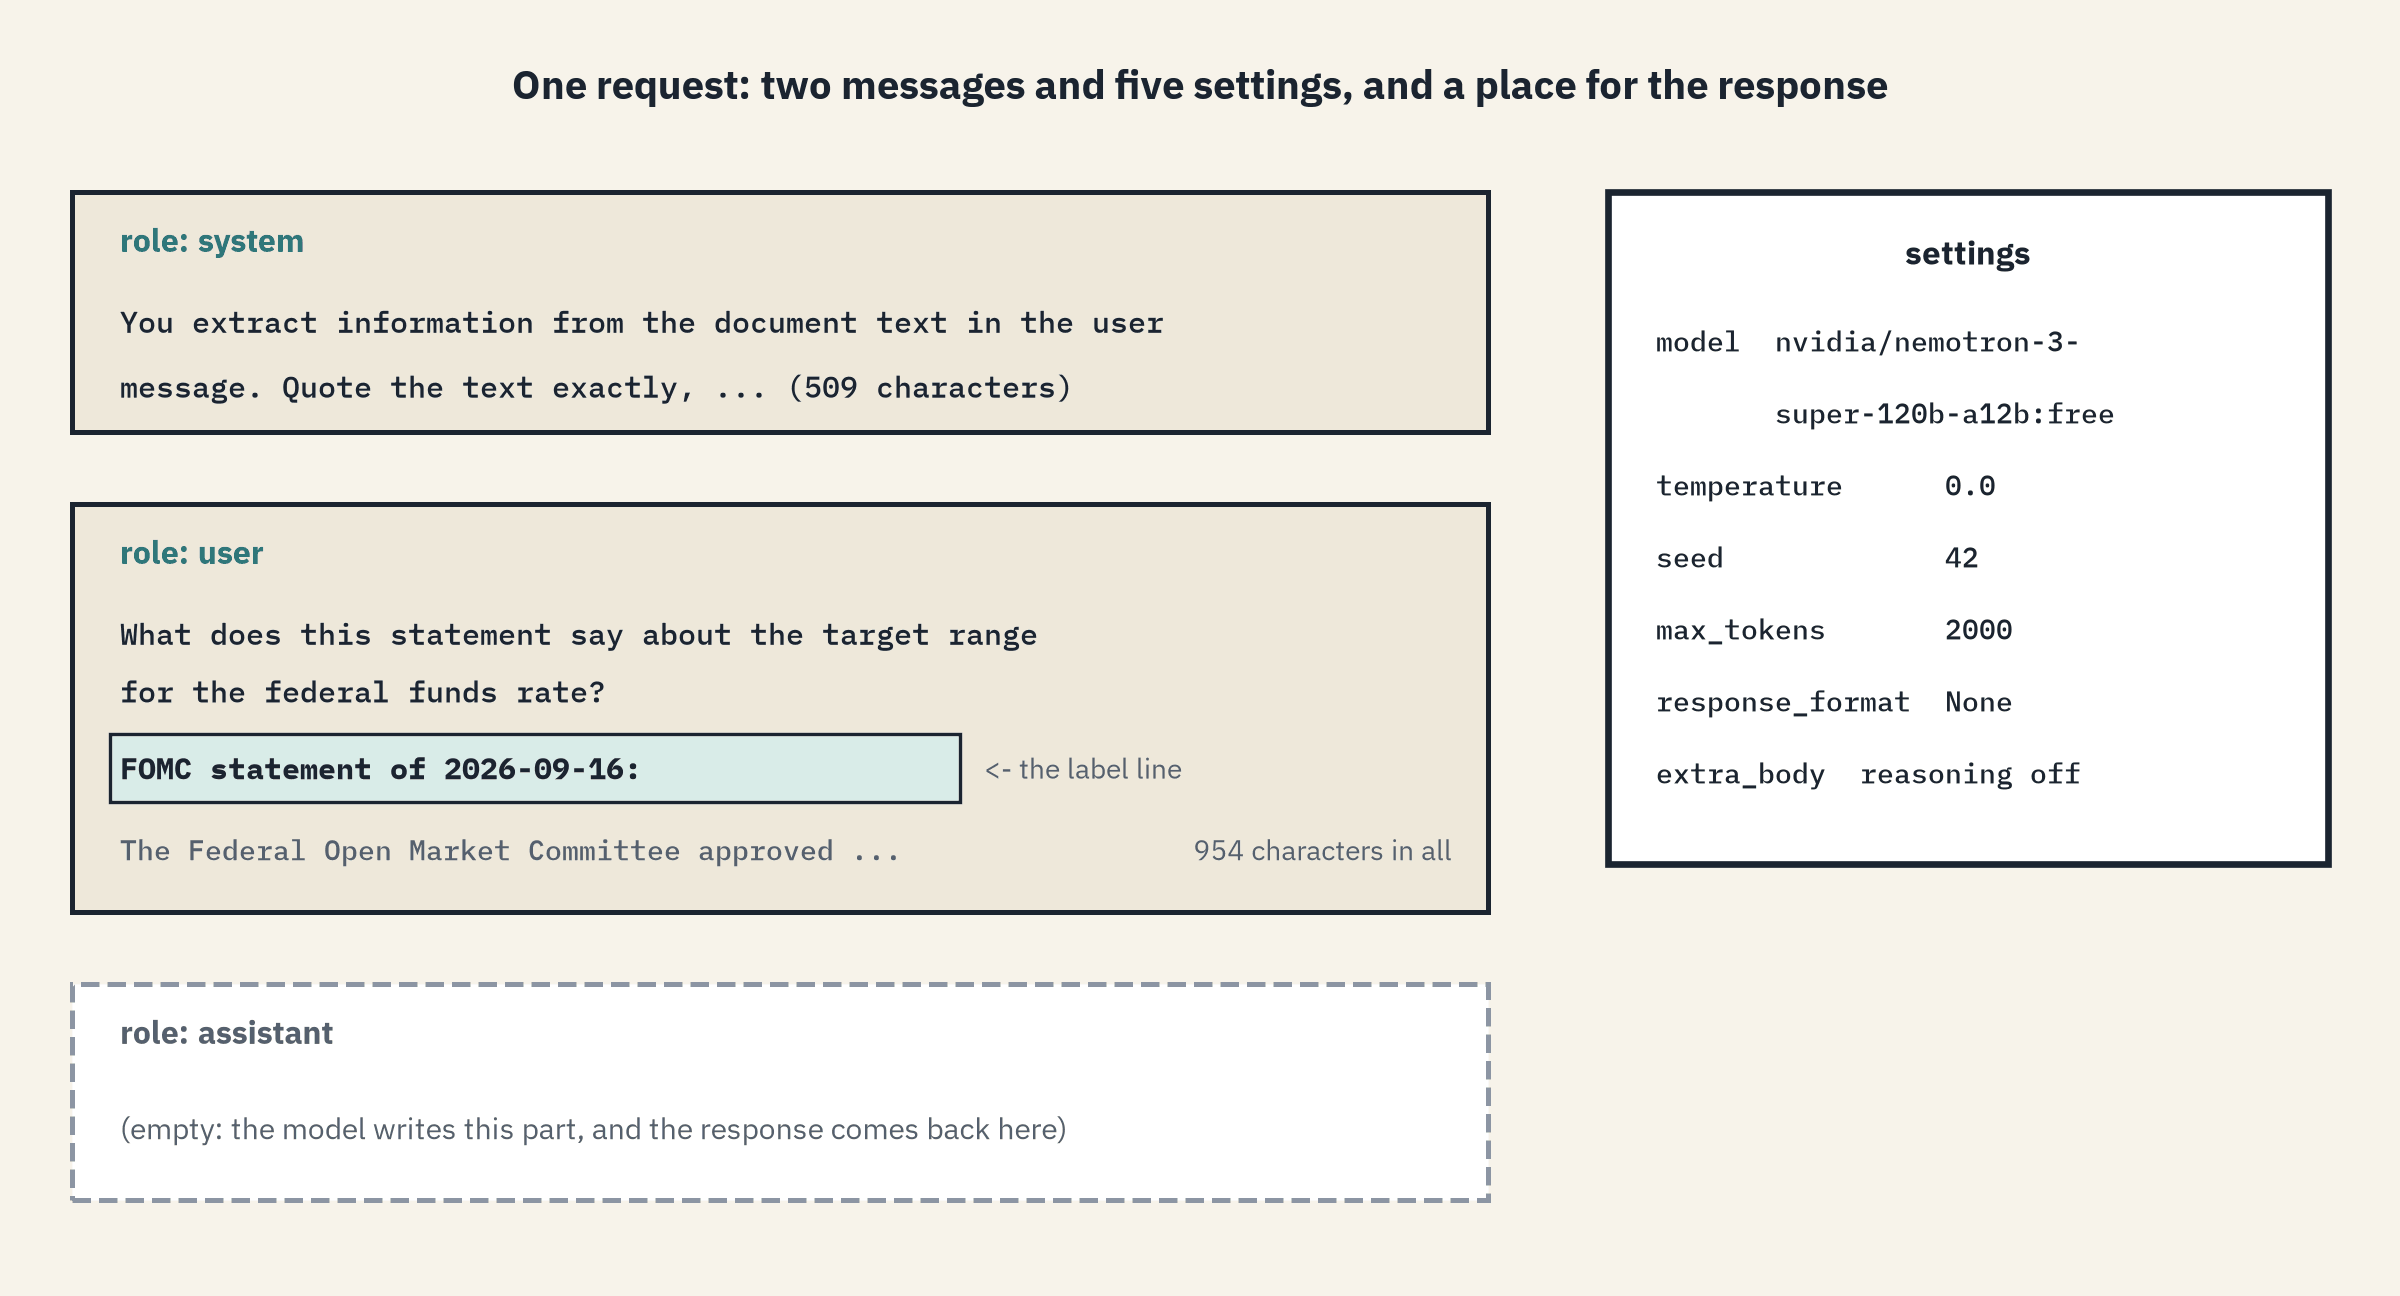

`temperature` and `seed` set how the model picks its words (Temperature and Seed, below).

`max_tokens` caps the length of the answer.

`response_format` None asks for plain text.

`extra_body` carries settings OpenRouter reads beyond the standard ones; this one switches reasoning off (Reasoning Switched Off, below).

**A request is two messages and five settings; nothing else reaches the model.**

# Sending the Request

## The Key Cell

Course 3 kept a key in three places: the environment, Colab's Secrets panel and `my_bondmath\.env`.
This cell looks in that order and makes the notebook's one **client**, or `None` when it finds no key.

In [10]:
# the key: the environment, then Colab's Secrets panel, then Course 3's .env file; never printed
key = os.environ.get("OPENROUTER_API_KEY")
if "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = key or userdata.get("OPENROUTER_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None
key = key or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENROUTER_API_KEY")
client = openai.OpenAI(base_url="https://openrouter.ai/api/v1", api_key=key, max_retries=0) if key else None
print(f"OpenRouter key loaded: {client is not None}. Mode: {'live' if client is not None else 'replay'}.")

OpenRouter key loaded: False. Mode: replay.


In Colab, `userdata.get` raises an error when the secret is missing or access was not granted; `except` catches those two only, as Course 3's key cell did.

The key and the client are never printed, and Course 3's `.gitignore` keeps `.env` out of Git.

`max_retries=0`: a refusal shows at once, not after the client has quietly tried again.

## Live or Replay

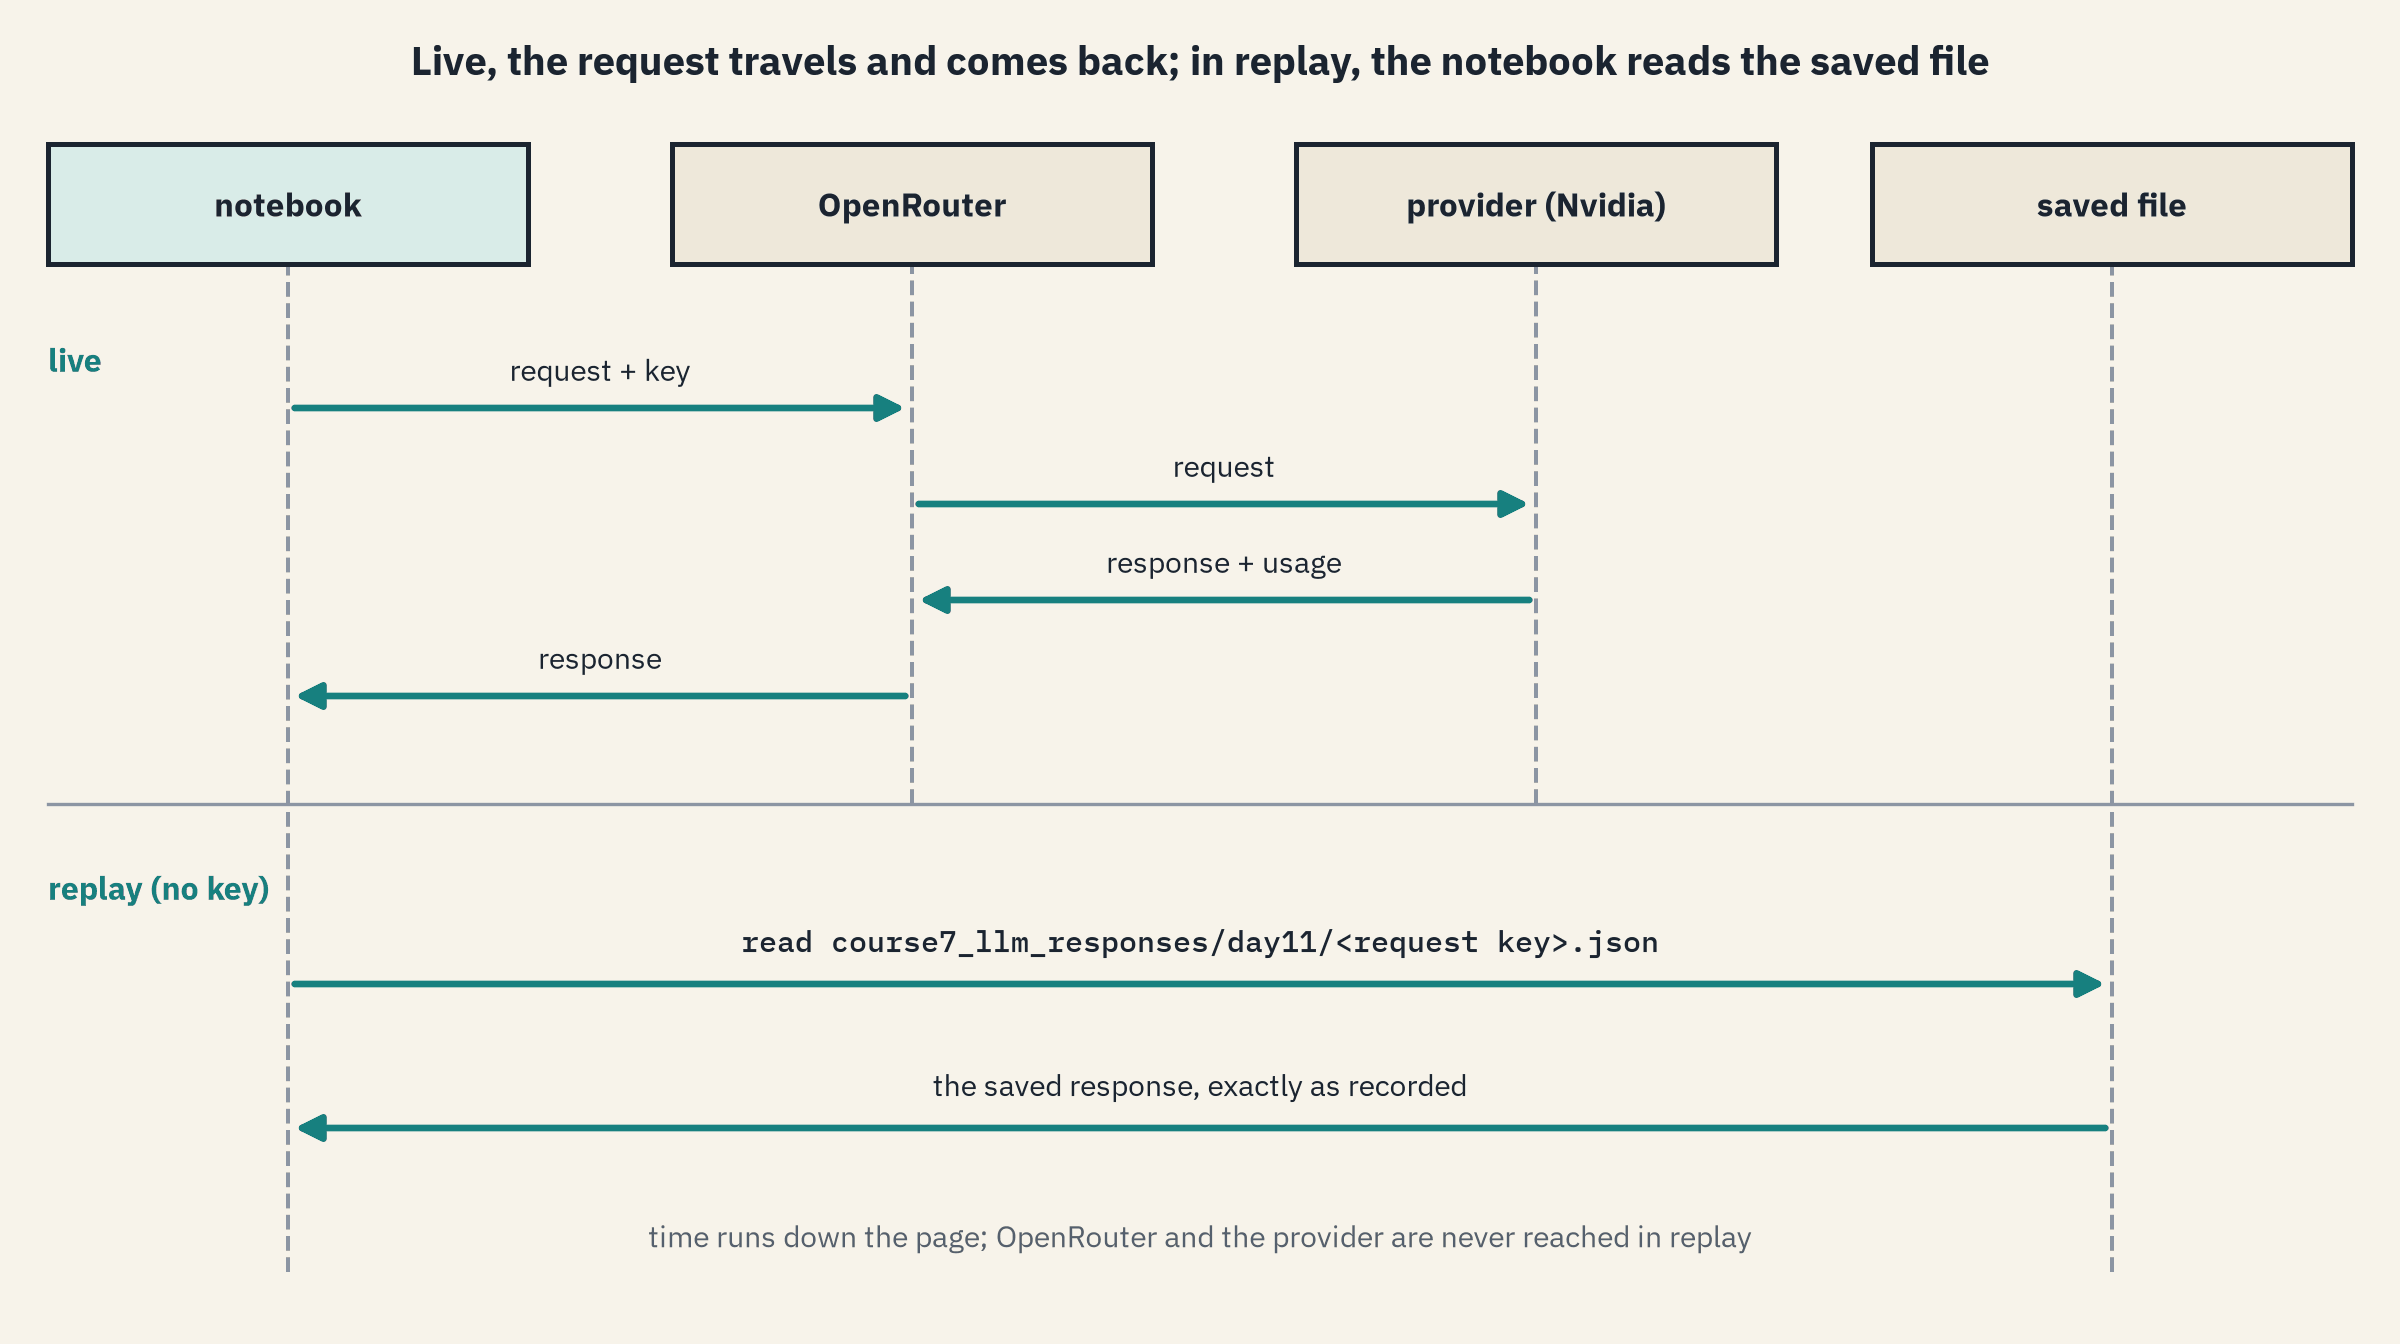

**OpenRouter** is one address that passes a request on to many models; the company that runs the model is the **provider**.
With no key, the notebook reads the response the course saved for exactly this request.

## The Request Key

`json.dumps(request, sort_keys=True, separators=(",", ":"))` writes a dictionary as one line of text, keys in order and no spaces, so the same request always gives the same text.
Course 4's `hashlib.sha256` turns that text into 64 hex characters: the **request key**, which names the saved file.

In [11]:
# the first request as one dictionary, and its fingerprint
def request_key(request):
    """The SHA-256 fingerprint of a request, as 64 hex characters."""
    text = json.dumps(request, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode("ascii")).hexdigest()


messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_message}]
request = {"provider": "openrouter", "model": TEXT_MODEL, "messages": messages, "params": params}
key_first = request_key(request)
print(key_first[:12], "...", len(key_first), "characters")

0e28d64e7792 ... 64 characters


## `ask`

`ask` builds the request, then replays the saved file named by its key when no key is loaded, or sends it live.

In [12]:
# one request: replayed from the course's saved file when no key is loaded, else sent live
def ask(user_message, model=TEXT_MODEL, extra_body=NO_REASONING, temperature=0.0, seed=SEED, max_tokens=2000,
        response_format=None, provider="openrouter", day="day11"):
    """The response to one request: the course's saved one when no key is loaded, else one sent live."""
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_message}]
    params = {"temperature": temperature, "seed": seed, "max_tokens": max_tokens, "response_format": response_format,
              "extra_body": extra_body}
    request = {"provider": provider, "model": model, "messages": messages, "params": params}
    # the notebook's one client is OpenRouter's, so a request on another route always replays
    if client is None or provider != "openrouter":
        saved = Path(data_file(f"course7_llm_responses/{day}/{request_key(request)}.json"))
        return json.loads(saved.read_text(encoding="utf-8"))
    # response_format is sent only when it is set
    options = {} if response_format is None else {"response_format": response_format}
    sent = client.chat.completions.create(model=model, messages=messages, temperature=temperature, seed=seed,
                                          max_tokens=max_tokens, extra_body=extra_body, **options)
    return {"content": sent.choices[0].message.content, "model": sent.model, "provider": sent.model_dump().get("provider"),
            "usage": sent.usage.model_dump(), "finish_reason": sent.choices[0].finish_reason, "recorded": "live",
            "request": request}

A live response comes back as an object, and `.model_dump()` turns it into a dictionary.

`ask` returns the same fields as a saved file either way, so every later cell runs live or replayed.

## The First Response

The **LLM line** under every response names the model, its settings and where the response came from.

In [13]:
# LLM response
# the line under every response: the model, the settings, and live or replayed
def llm_line(response):
    """Print the model, the temperature and seed, and where the response came from."""
    settings = response["request"]["params"]
    if response["recorded"] == "live":
        where = "live."
    elif client is None:
        where = f"saved response recorded {response['recorded']}; replayed (no key loaded)."
    else:
        where = f"saved response recorded {response['recorded']}; replayed (not the client's route)."
    print(f"Model {response['request']['model']}, temperature {settings['temperature']}, seed {settings['seed']}; {where}")


# the first request, and its response through normalize_text
response = ask(user_message)
print(normalize_text(response["content"]))
llm_line(response)

The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate.
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


A response is text from outside the course, so it is printed through `normalize_text`, as a filing is.

The response is one sentence; Day 5's `policy_action` read this statement as a raise too.

## Checking the Range Against the Statement

In [14]:
# Day 1's NUMBER and RANGE, on the statement and on the response
NUMBER = r"(?:\d+[- ]\d+/\d+|\d+/\d+|\d+)"
RANGE = (rf"target range for the federal funds rate(?: by {NUMBER} percentage point,?)?"
         rf" (?:at|to|of) (?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent")
answer = normalize_text(response["content"])
print("statement:", re.search(RANGE, statement).groups(), "| response:", re.search(RANGE, answer).groups())
print("the response's sentence is in the statement word for word:", answer in statement)

statement: ('3-3/4', '4') | response: ('3-3/4', '4')
the response's sentence is in the statement word for word: True


**We use the answer because code that never touched the model found the same range in the statement.**

# Temperature and Seed

## How a Model Picks Its Next Word

A model writes its answer one piece at a time; at each step it gives every possible next piece a chance and draws one.
The seven chances below, after "Inflation remains", are invented to show the idea: not a model's numbers, and not a reading of inflation.

In [15]:
# seven invented chances for the next word after "Inflation remains"
chances = pd.Series({"elevated": 0.46, "high": 0.22, "sticky": 0.12, "above": 0.08, "firm": 0.06, "moderate": 0.04,
                     "subdued": 0.02})
print(chances.to_dict(), "| sum:", round(chances.sum(), 2))

{'elevated': 0.46, 'high': 0.22, 'sticky': 0.12, 'above': 0.08, 'firm': 0.06, 'moderate': 0.04, 'subdued': 0.02} | sum: 1.0


## Your Turn: Temperature on the Chances

**Temperature** reshapes the chances before the draw: each is raised to the power 1 / temperature, then all are rescaled to add up to 1.
Drag it below 1 and above 1.

In [16]:
# the chances at the temperature you pick
def draw_chances(temperature=1.0):
    weights = chances ** (1 / temperature)
    weights = weights / weights.sum()
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(weights.index, weights, color="C0")
    ax.set(ylim=(0, 1), xlabel='Next word after "Inflation remains"', ylabel="Chance (invented)")
    ax.set_title(f"At Temperature {temperature:.1f}, Elevated Takes {weights['elevated']:.0%} of the Chance")
    plt.show()


interact(draw_chances, temperature=(0.1, 2.0, 0.1));

interactive(children=(FloatSlider(value=1.0, description='temperature', max=2.0, min=0.1), Output()), _dom_cla…

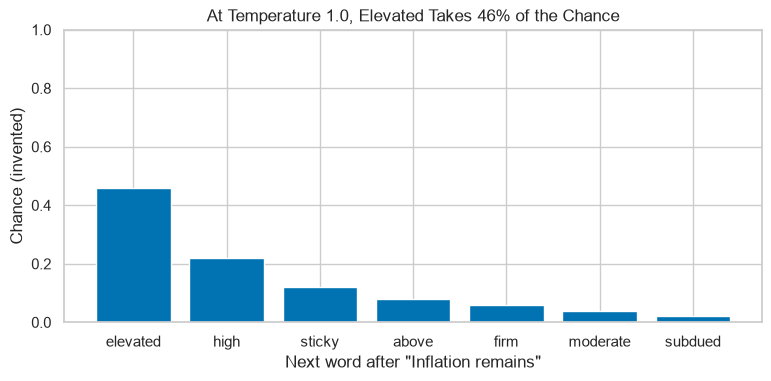

In [17]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_chances(temperature=1.0)

## Every Chance Against Temperature

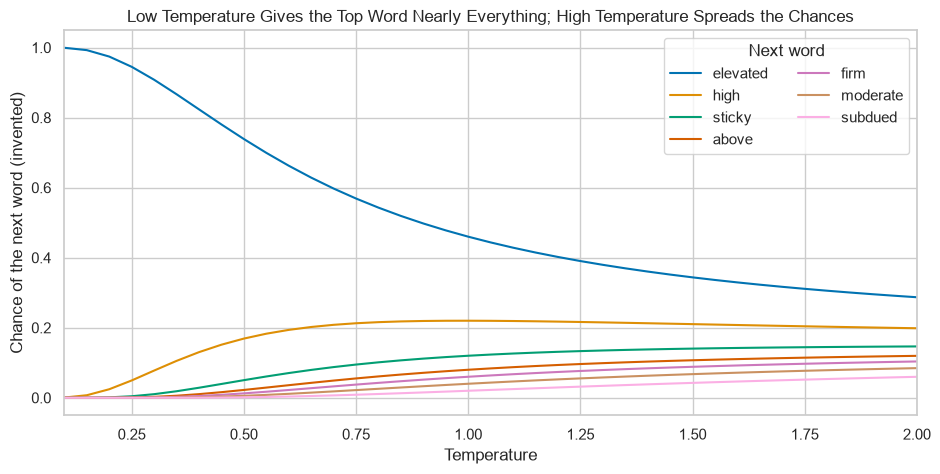

elevated: {0.1: 0.999, 0.5: 0.739, 2.0: 0.287}


In [18]:
# each word's chance at temperatures from 0.1 to 2.0, one line a word
temperatures = np.round(np.arange(0.1, 2.01, 0.05), 2)
curves = pd.DataFrame({t: chances ** (1 / t) / (chances ** (1 / t)).sum() for t in temperatures}).T
ax = curves.plot(figsize=(11, 5))
ax.legend(title="Next word", loc="upper right", ncols=2)
ax.set(xlabel="Temperature", ylabel="Chance of the next word (invented)", xlim=(0.1, 2.0))
ax.set_title("Low Temperature Gives the Top Word Nearly Everything; High Temperature Spreads the Chances")
plt.show()
print("elevated:", curves.loc[[0.1, 0.5, 2.0], "elevated"].round(3).to_dict())

At 0.1 "elevated" takes 0.999 of the chance; at 2.0 it holds 0.287.

Temperature 0 is the limit: the top word every time.

A **seed** fixes the random draws, so the same request should draw the same way; a provider takes a seed as a request, not a promise.

**Predict 1**

The course sent one summary request at temperature 0.0 three times, with seeds 42, 43 and 44.

Q. How many different texts came back? Write down a number.

## One Request, Six Saved Responses

`SUMMARY` asks for one sentence on inflation, sent at temperatures 0.0 and 1.0, each with seeds 42, 43 and 44.

In [19]:
# LLM response
# the summary request at two temperatures and three seeds, each response with its LLM line
SUMMARY = "In one sentence, summarise what this statement says about inflation."
summary_message = f"{SUMMARY}\n\nFOMC statement of {row['date']}:\n{statement}"
six = []
for temperature in [0.0, 1.0]:
    for seed in [42, 43, 44]:
        saved = ask(summary_message, temperature=temperature, seed=seed)
        six.append(saved)
        print(normalize_text(saved["content"]))
        llm_line(saved)

Inflation remains elevated, and today's policy action will support a timelier return to the Committee's 2 percent goal, with the Committee committed to delivering price stability.
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Inflation remains elevated, and today's policy action will support a timelier return to the Committee's 2 percent goal, with the Committee committed to delivering price stability.
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 43; saved response recorded 2026-10-08; replayed (no key loaded).
Inflation remains elevated, and the Committee's policy action is intended to support a timelier return to its 2 percent goal and deliver price stability.
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 44; saved response recorded 2026-10-08; replayed (no key loaded).
Inflation remains elevated, and the rate increase aims to support a timelier return 

In [20]:
# the six as a table, then how many different texts at each temperature and in all
summaries = pd.DataFrame({"temperature": [s["request"]["params"]["temperature"] for s in six],
                          "seed": [s["request"]["params"]["seed"] for s in six],
                          "text": [normalize_text(s["content"]) for s in six]})
print(summaries.groupby("temperature")["text"].nunique().to_dict(), "| in all:", summaries["text"].nunique())

# the words of each response with a token the statement never uses (any() is True when one token is missing)
in_statement = set(tokenize(statement))
summaries["new words"] = [[word for word in text.split() if any(token not in in_statement for token in tokenize(word))]
                          for text in summaries["text"]]
print(summaries[["temperature", "seed", "new words"]].to_string(index=False))

{0.0: 2, 1.0: 3} | in all: 5
 temperature  seed                 new words
         0.0    42   [committed, delivering]
         0.0    43   [committed, delivering]
         0.0    44                [intended]
         1.0    42 [increase, aims, achieve]
         1.0    43                     [but]
         1.0    44                     [but]


## The Six Side by Side

Each response is one row of word boxes; the arrow style `"-["` draws the bracket that joins the two identical rows.

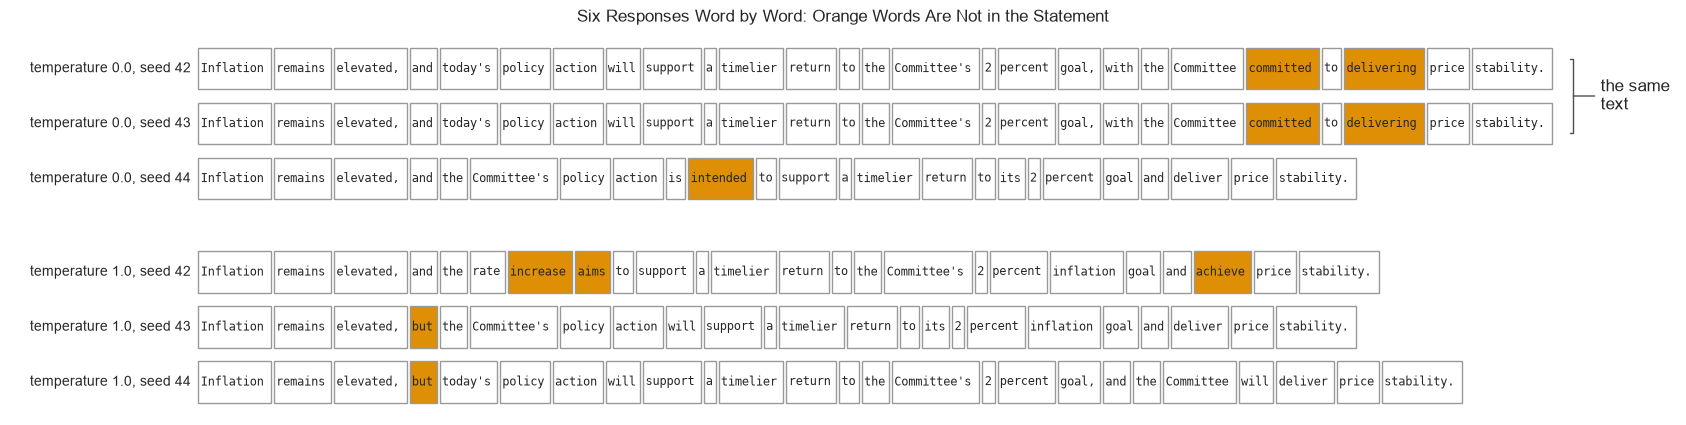

In [21]:
# each summary as a row of word boxes, one character a unit, orange where the word is new; the identical rows bracketed
fig, ax = plt.subplots(figsize=(17, 5))
fig.subplots_adjust(left=0.01, right=0.99)
for i, (temperature, seed, text, new_words) in enumerate(summaries.itertuples(index=False)):
    x, y = 0, -i - 0.7 * (temperature > 0)
    for word in text.split():
        ax.add_patch(plt.Rectangle((x, y - 0.38), len(word) + 0.6, 0.76, facecolor="C1" if word in new_words else "white", edgecolor="0.6"))
        ax.text(x + 0.3, y, word, va="center", fontsize=8.5, family="monospace")
        x += len(word) + 1
    ax.text(-1, y, f"temperature {temperature}, seed {seed}", ha="right", va="center", fontsize=10)
ax.annotate("the same\ntext", xy=(182, -0.5), xytext=(186, -0.5), va="center", arrowprops={"arrowstyle": "-[, widthB=2.2", "color": "0.3"})
ax.set(xlim=(-25, 196), ylim=(-6.3, 0.7), title="Six Responses Word by Word: Orange Words Are Not in the Statement")
ax.set_axis_off()
plt.show()

### Interpretation of the Six

All six open "Inflation remains elevated,", the statement's own words.

At temperature 0.0, seeds 42 and 43 return one text and seed 44 another; at 1.0 each seed returns its own.

The orange words are the model's own: "committed" and "delivering", "intended", "increase", "aims" and "achieve", and "but" twice.

**Temperature 0 and a seed narrow the spread and promise nothing, so the course checks every answer and saves every response.**

# Replay and the Request Key

## The Same Request Again

In [22]:
# the first request once more: the same key, so the same saved file and the same text
again = ask(user_message)
print(request_key(again["request"])[:12], "| the same text as the first time:", again["content"] == response["content"])

0e28d64e7792 | the same text as the first time: True


**Predict 2**

Q. Add two words, " Quote it.", to the end of the question. How many of the key's 64 characters change? Write down a number.

## Two Words Added

In [23]:
# the question with two words added, as a request, and its key against the first
changed_message = f"{QUESTION} Quote it.\n\nFOMC statement of {row['date']}:\n{statement}"
changed_request = {"provider": "openrouter", "model": TEXT_MODEL, "params": params,
                   "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": changed_message}]}
key_changed = request_key(changed_request)
differ = np.array([a != b for a, b in zip(key_first, key_changed)])
print(key_changed[:12], "|", differ.sum(), "of 64 characters differ")

dd2ca18e0b82 | 60 of 64 characters differ


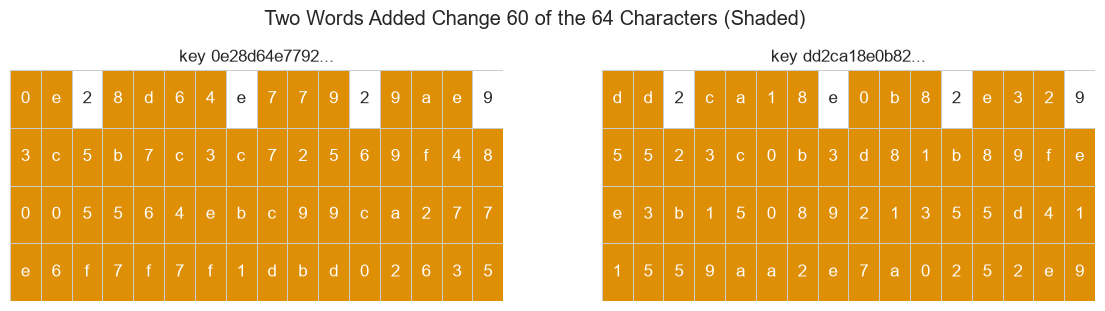

In [24]:
# the two keys as 4 rows of 16 characters, a character shaded where the keys differ
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
for ax, shown in zip(axes, [key_first, key_changed]):
    sns.heatmap(differ.reshape(4, 16), annot=np.array(list(shown)).reshape(4, 16), fmt="", cmap=["white", "#DE8F05"],
                cbar=False, linewidths=0.5, linecolor="0.8", xticklabels=False, yticklabels=False, ax=ax)
    ax.set_title(f"key {shown[:12]}...")
fig.suptitle("Two Words Added Change 60 of the 64 Characters (Shaded)", y=1.08)
plt.show()

A small change to the text gives a key with almost nothing in common, so no answer is ever filed under the wrong request.

## A Request the Course Never Saved

`ask` stops at its line that reads the saved file, and Python's error names the file it looked for.
In Colab the download fails instead, with HTTP Error 404.

In [25]:
# the changed question through ask: no response was saved for it
ask(changed_message)

FileNotFoundError: [Errno 2] No such file or directory: '..\\..\\..\\data\\course7_llm_responses\\day11\\dd2ca18e0b82e3295523c0b3d81b89fee3b1508921355d411559aa2e7a0252e9.json'

## 0 Is Not 0.0

In [26]:
# the first request with temperature written 0 instead of 0.0 (dict(params, temperature=0) copies params with one change)
zero_request = dict(request, params=dict(params, temperature=0))
key_zero = request_key(zero_request)
print(key_zero[:12], "|", sum(a != b for a, b in zip(key_first, key_zero)), "of 64 characters differ")
print(json.dumps(params["temperature"]), "against", json.dumps(0))

3b24923826cd | 58 of 64 characters differ
0.0 against 0


`json.dumps` writes 0.0 and 0 differently, so the key changes; every request in the course writes 0.0.

**The key fingerprints the request's text, so a changed prompt never passes with an old answer.**

# Tokens and Cost

## What Comes Back

In [27]:
# the fields of the first response, why it stopped, the model that answered and who ran it
print(list(response))
print(response["finish_reason"], "|", response["model"], "|", response["provider"])

['content', 'finish_reason', 'model', 'provider', 'recorded', 'request', 'usage']
stop | nvidia/nemotron-3-super-120b-a12b:free | Nvidia


`finish_reason` "stop": the model ended its answer itself.

OpenRouter chose the provider, Nvidia, to run the model.

## A Cut Answer

In [28]:
# LLM response
# the first request with max_tokens=20: the answer is cut where the cap falls
short = ask(user_message, max_tokens=20)
print(normalize_text(short["content"]))
print("range found:", re.search(RANGE, normalize_text(short["content"])) is not None, "| finish_reason:", short["finish_reason"])
llm_line(short)

The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point
range found: False | finish_reason: length
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


`finish_reason` "length": the cap stopped the answer before the range, and `RANGE` finds nothing.

## Day 1's Tokens in What We Send

In [29]:
# the two messages of the first request: Day 1's tokens, words and characters
system_tokens, user_tokens = len(tokenize(SYSTEM_PROMPT)), len(tokenize(user_message))
words_sent = len(SYSTEM_PROMPT.split()) + len(user_message.split())
characters_sent = len(SYSTEM_PROMPT) + len(user_message)
print("Day 1's tokens:", system_tokens, "+", user_tokens, "=", system_tokens + user_tokens, "|", words_sent, "words |",
      characters_sent, "characters")

Day 1's tokens: 89 + 150 = 239 | 238 words | 1463 characters


**Predict 3**

Day 1's `tokenize` counts 239 tokens in the two messages.

Q. How many prompt tokens did the provider bill for them? Write down a number.

## The Tokens One Request Uses

`usage` is what the provider counted and billed, in the model's own **tokens**: pieces of text from the model's vocabulary, often part of a word, plus a few that mark each message's role.
The **prompt tokens** are what was sent; the **completion tokens** what came back.

prompt tokens: 323 | completion tokens: 43 | total: 366


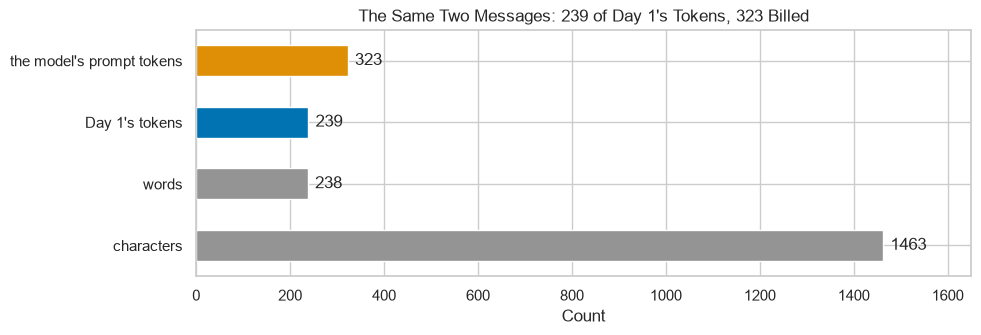

In [30]:
# the first response's usage, then four counts of what was sent
usage = response["usage"]
print("prompt tokens:", usage["prompt_tokens"], "| completion tokens:", usage["completion_tokens"], "| total:", usage["total_tokens"])
sizes = pd.Series({"characters": characters_sent, "words": words_sent, "Day 1's tokens": system_tokens + user_tokens,
                   "the model's prompt tokens": usage["prompt_tokens"]})
ax = sizes.plot.barh(figsize=(10, 3.2), color=["C7", "C7", "C0", "C1"])
for y, value in enumerate(sizes):
    ax.text(value + 15, y, value, va="center")
ax.set(xlabel="Count", xlim=(0, 1650), title="The Same Two Messages: 239 of Day 1's Tokens, 323 Billed")
plt.show()

The provider billed 323 prompt tokens for what Day 1 counts as 239: its tokenizer cuts words into pieces and marks each role.

That is about 4.5 characters a token.

Day 6's word pieces came from MiniLM's tokenizer; these come from the provider's.

## The Price of a Token

Free models cost nothing.
On the recording date the paid fallback, `google/gemini-2.5-flash-lite`, was listed at US$0.10 per million prompt tokens and US$0.40 per million completion tokens.
Its page on OpenRouter lists several prices for it today, these two among them (https://openrouter.ai/google/gemini-2.5-flash-lite, read 2026-11-18); prices change, so the course keeps the recording date's.

In [31]:
# prices per token, as text so every digit is the one written: (prompt, completion) in US$
FALLBACK_MODEL = "google/gemini-2.5-flash-lite"
PRICES = {TEXT_MODEL: ("0", "0"), FALLBACK_MODEL: ("0.0000001", "0.0000004")}
for model, (prompt_price, completion_price) in PRICES.items():
    print(f"{model}: US${float(prompt_price) * 1e6:.2f} and US${float(completion_price) * 1e6:.2f} per million tokens")

nvidia/nemotron-3-super-120b-a12b:free: US$0.00 and US$0.00 per million tokens
google/gemini-2.5-flash-lite: US$0.10 and US$0.40 per million tokens


## The Same Request on the Paid Fallback

The course sent the fallback the first request without `NO_REASONING`, as recorded.

In [32]:
# LLM response
# the first request on the fallback: the response, its two counts, the cost by hand and the cost it was billed
fallback = ask(user_message, model=FALLBACK_MODEL, extra_body=None)
print(normalize_text(fallback["content"]))
prompt_price, completion_price = PRICES[FALLBACK_MODEL]
by_hand = fallback["usage"]["prompt_tokens"] * float(prompt_price) + fallback["usage"]["completion_tokens"] * float(completion_price)
print("prompt tokens:", fallback["usage"]["prompt_tokens"], "| completion tokens:", fallback["usage"]["completion_tokens"],
      f"| by hand US${by_hand:.7f} | billed US${fallback['usage']['cost']:.7f}")
llm_line(fallback)

"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent" (Section 1)
prompt tokens: 308 | completion tokens: 38 | by hand US$0.0000460 | billed US$0.0000460
Model google/gemini-2.5-flash-lite, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The by-hand cost equals what the response says it was billed, so these were the prices charged.

Two tokenizers: 308 prompt tokens here, 323 on the free model, for the same text.

A statement has no sections, yet the response names "Section 1".

In [33]:
# the first request at the fallback's list price, once and a thousand times
first_cost = usage["prompt_tokens"] * float(prompt_price) + usage["completion_tokens"] * float(completion_price)
print(f"one request: US${first_cost:.7f} | 1,000 requests: US${1000 * first_cost:.4f}")
print(f"the prompt's share of the tokens: {usage['prompt_tokens'] / usage['total_tokens']:.0%}")

one request: US$0.0000495 | 1,000 requests: US$0.0495
the prompt's share of the tokens: 88%


**A request is billed in tokens, and the document is most of them.**

# Reasoning Switched Off

Some models write working text before the answer, called **reasoning**.
It is not returned in `content`, and it is billed as completion tokens.
`NO_REASONING`, sent through `extra_body`, switches it off on the free model; the course recorded the first request once with `extra_body=None`, reasoning on.

**Predict 4**

With reasoning off, the first answer took 43 completion tokens.

Q. With reasoning on, how many? Write down a number.

## The First Request With Reasoning On

In [34]:
# LLM response
# the first request with reasoning on: the response, its completion tokens, and how many of them were reasoning
reasoning_on = ask(user_message, extra_body=None)
print(normalize_text(reasoning_on["content"]))
hidden = reasoning_on["usage"]["completion_tokens_details"]["reasoning_tokens"]
reasoning_on_cost = reasoning_on["usage"]["prompt_tokens"] * float(prompt_price) + reasoning_on["usage"]["completion_tokens"] * float(completion_price)
print("completion tokens:", reasoning_on["usage"]["completion_tokens"], "| reasoning among them:", hidden)
print(f"at the fallback's list price: US${reasoning_on_cost:.7f} against US${first_cost:.7f}, {reasoning_on_cost / first_cost:.2f} times")
llm_line(reasoning_on)

"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent," - Section 1
completion tokens: 1261 | reasoning among them: 1222
at the fallback's list price: US$0.0005367 against US$0.0000495, 10.84 times
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


## The Hidden Part

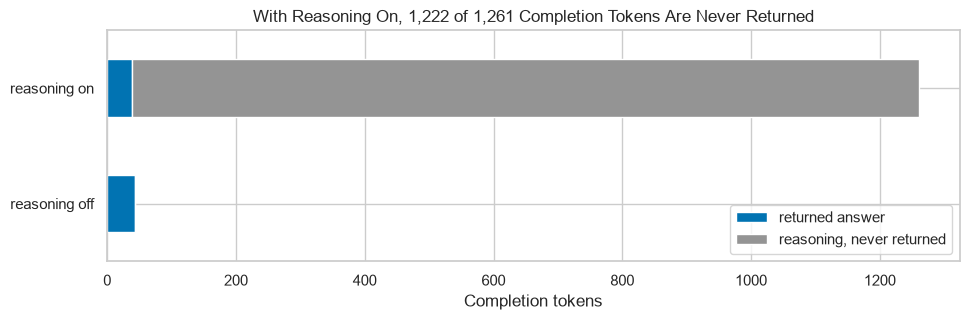

               returned answer  reasoning, never returned
reasoning off               43                          0
reasoning on                39                       1222


In [35]:
# completion tokens with reasoning off and on: the returned answer, and the reasoning never returned
parts = pd.DataFrame({"returned answer": [response["usage"]["completion_tokens"], reasoning_on["usage"]["completion_tokens"] - hidden],
                      "reasoning, never returned": [0, hidden]}, index=["reasoning off", "reasoning on"])
ax = parts.plot.barh(stacked=True, figsize=(11, 3), color=["C0", "C7"])
ax.set(xlabel="Completion tokens", title="With Reasoning On, 1,222 of 1,261 Completion Tokens Are Never Returned")
plt.show()
print(parts)

The two returned answers are about the same size, 43 and 39 tokens; the reasoning is 1,222 tokens on top.

**Reasoning stays off where the text holds the answer: the course asks the model to find and quote.**

# The System Prompt on One Paragraph

## Two Questions, One Paragraph

In [36]:
# LLM response
# two questions on paragraph (b): one the paragraph answers, one it does not
EQUITY_QUESTION = "What share of the Notes may the Company redeem with the proceeds of Equity Offerings, and at what redemption price?"
INTEREST_QUESTION = "What is the interest rate on the Notes?"
paragraph_answers = []
for question in [EQUITY_QUESTION, INTEREST_QUESTION]:
    saved = ask(f"{question}\n\nSection 3.07 of the indenture, one paragraph:\n{paragraph}")
    paragraph_answers.append(saved)
    print(question, "->", normalize_text(saved["content"]), "| completion tokens:", saved["usage"]["completion_tokens"])
    llm_line(saved)

What share of the Notes may the Company redeem with the proceeds of Equity Offerings, and at what redemption price? -> The Company may redeem up to 40% of the aggregate principal amount of Notes with the proceeds of Equity Offerings at a redemption price of 104.750% of the principal amount thereof, plus accrued and unpaid interest and Additional Interest, if any, to the redemption date. This is stated in Section 3.07(b) of the indenture. | completion tokens: 82
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
What is the interest rate on the Notes? -> NOT IN TEXT | completion tokens: 4
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The equity question returns both numbers and cites "Section 3.07(b)".

The interest question returns NOT IN TEXT in 4 completion tokens: the paragraph states no interest rate, and the system prompt makes that a response.

## Checking Each Percentage

In [37]:
# every percentage in the equity response, and whether the paragraph holds it
equity = normalize_text(paragraph_answers[0]["content"])
percents = re.findall(r"\d+(?:\.\d+)?%", equity)
print([(percent, percent in paragraph) for percent in percents])
print('"4.750%" in the paragraph by a plain in test:', "4.750%" in paragraph)

[('40%', True), ('104.750%', True)]
"4.750%" in the paragraph by a plain in test: True


### Interpretation of the Check

Both percentages in the response are in the paragraph.

The coupon, 4.750%, is in the source line's title, which was never sent.

A plain `in` test still finds "4.750%", inside "104.750%": Exercise 3 writes a test that does not.

**The response comes from the text sent, and the system prompt makes NOT IN TEXT a response we can test for.**

# When a Request Fails

## Four Codes in Plain Words

Course 3 met 400 and 429, and Day 9 waited and tried again after a 429.
A request to a model meets two more: 401 and 402.

In [38]:
# four refusals, the openai error each raises, and whether waiting helps
codes = pd.DataFrame({"code": [400, 401, 402, 429],
                      "openai error": ["BadRequestError", "AuthenticationError", "APIStatusError", "RateLimitError"],
                      "meaning": ["the request is wrong: a model id or a setting", "the key is missing, wrong or revoked",
                                  "no credit left for a paid model", "too many requests: a cap is reached"],
                      "waiting helps": ["no", "no", "no", "the per-minute cap only"]})
print(codes.to_string(index=False))
print("tries again by itself unless told otherwise:", openai.DEFAULT_MAX_RETRIES, "times")

 code        openai error                                       meaning           waiting helps
  400     BadRequestError the request is wrong: a model id or a setting                      no
  401 AuthenticationError          the key is missing, wrong or revoked                      no
  402      APIStatusError               no credit left for a paid model                      no
  429      RateLimitError           too many requests: a cap is reached the per-minute cap only
tries again by itself unless told otherwise: 2 times


The key cell's `max_retries=0` turns those 2 quiet retries off.

## A Stand-In That Answers 429

Like Day 9's stand-in session, `refuse` answers in place of the provider, so we see the error and send nothing.
`SimpleNamespace(...)` makes a small object with the attributes we name, here a response's status code.

In [39]:
# a stand-in that answers every request as a provider does at its cap: nothing is sent
def refuse(model, messages):
    """Answer every request the way a provider answers when its cap is reached."""
    response = SimpleNamespace(status_code=429, headers={}, request=None)
    raise openai.RateLimitError("HTTP 429: too many requests", response=response, body=None)


refuse(model=TEXT_MODEL, messages=messages)

RateLimitError: HTTP 429: too many requests

## Two Caps on One Clock

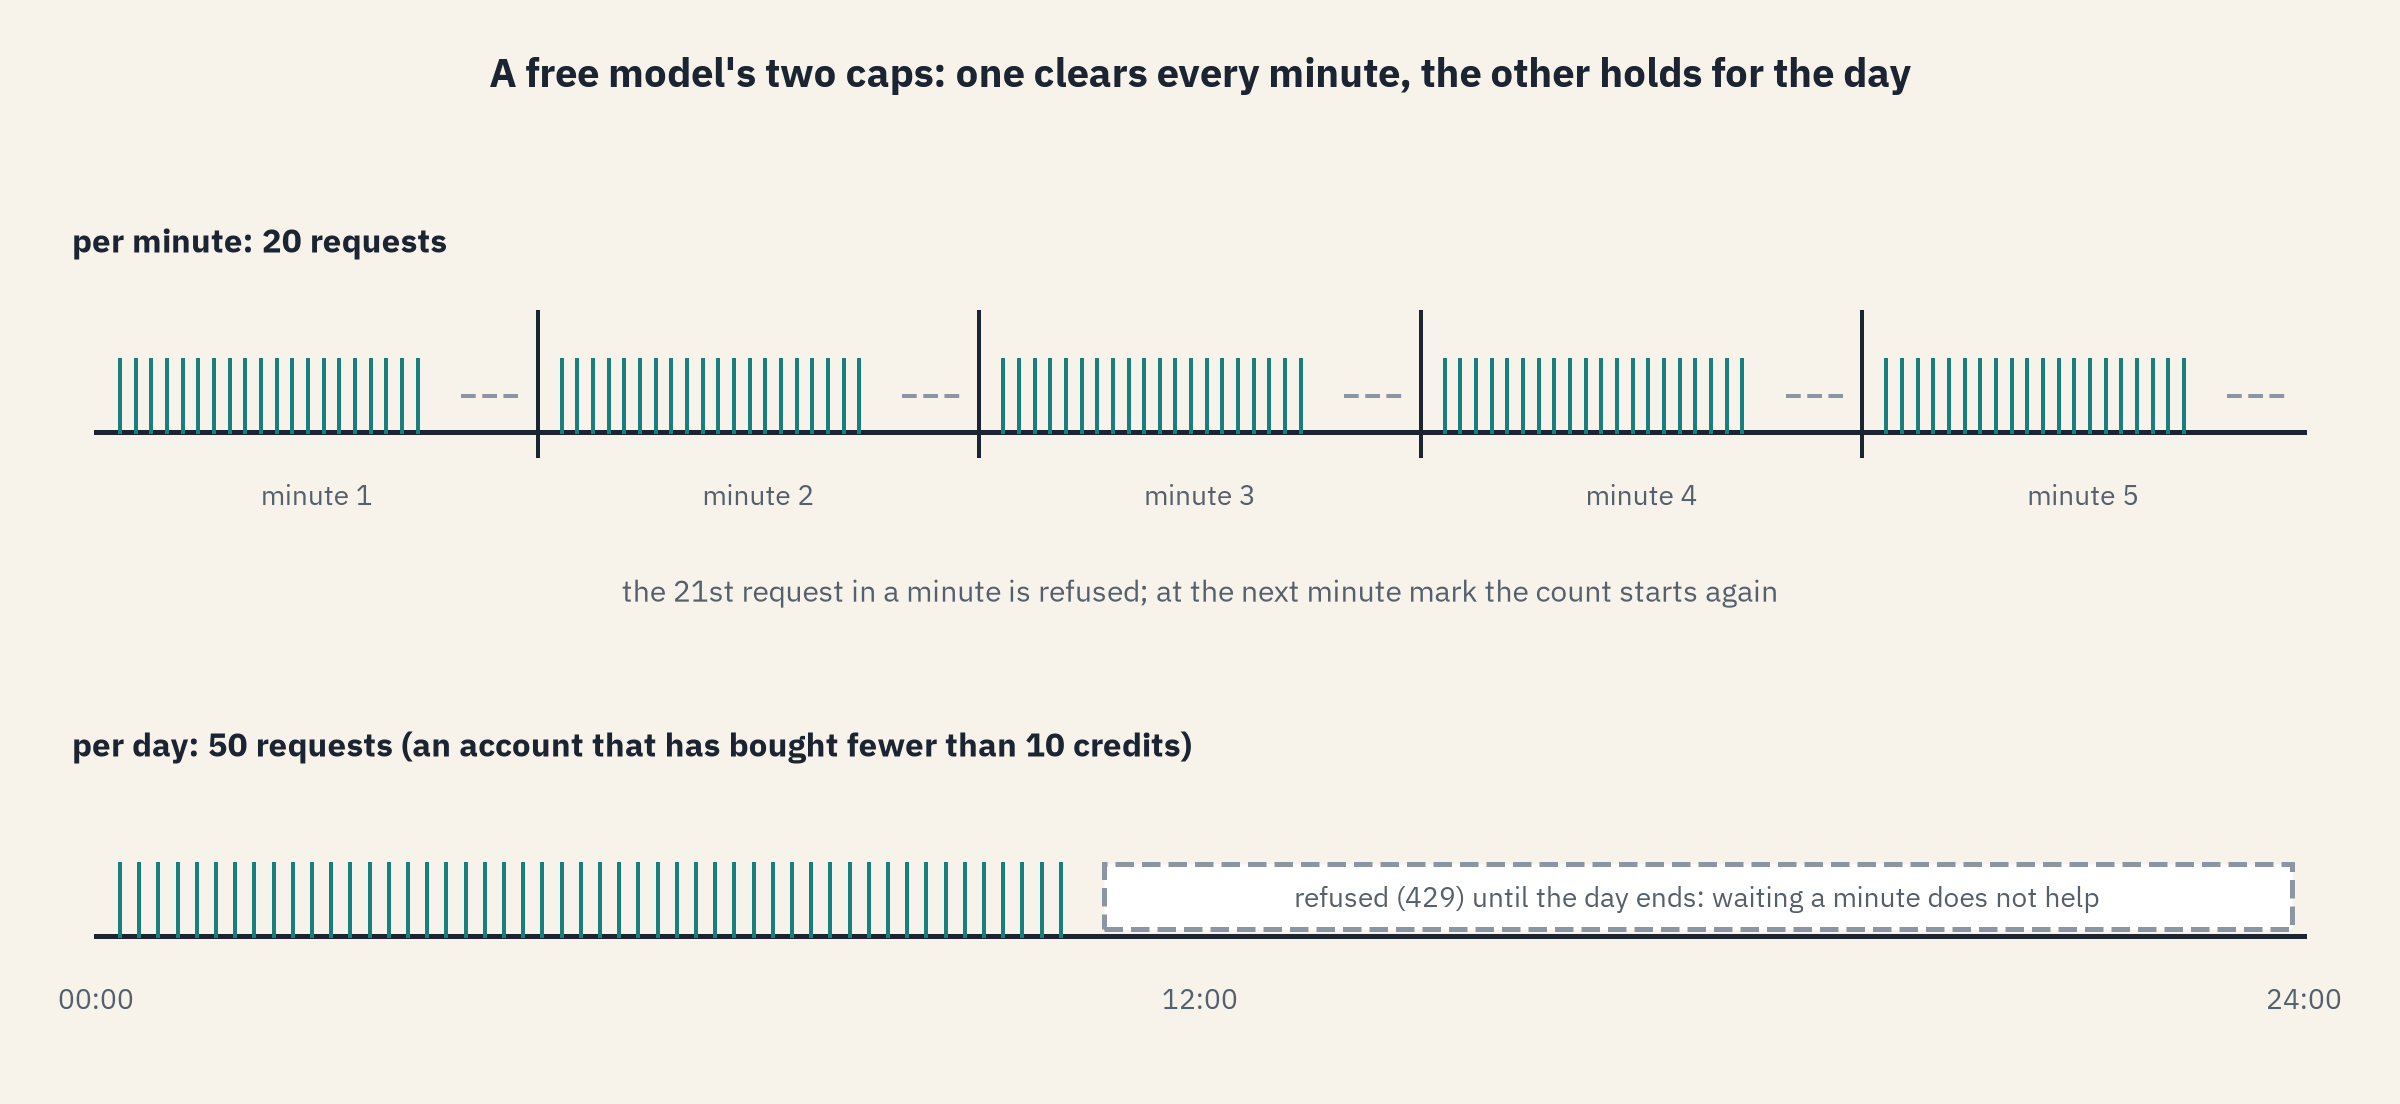

OpenRouter's limits page (https://openrouter.ai/docs/api-reference/limits, read 2026-11-18) caps a `:free` model at 20 requests a minute.
It also caps it at 50 a day for an account that has bought fewer than 10 credits, and 1,000 a day from 10.

**Waiting clears a per-minute cap, not a daily one; replay needs neither a key nor a cap.**

# The OpenAI Route

## Only the Address and the Key's Name Change

In [40]:
# the two routes: the client's base_url, the name of the key, and the model the course sent
ROUTES = pd.DataFrame({"openrouter": ["https://openrouter.ai/api/v1", "OPENROUTER_API_KEY", TEXT_MODEL],
                       "openai": ["https://api.openai.com/v1", "OPENAI_API_KEY", "gpt-4.1-mini"]},
                      index=["base_url", "key name", "model"]).T
print(ROUTES.to_string())

                                base_url            key name                                   model
openrouter  https://openrouter.ai/api/v1  OPENROUTER_API_KEY  nvidia/nemotron-3-super-120b-a12b:free
openai         https://api.openai.com/v1      OPENAI_API_KEY                            gpt-4.1-mini


The notebook's one client is OpenRouter's, so `ask` replays a request on the OpenAI route every time.

## The First Question on OpenAI

In [41]:
# LLM response
# the first request on OpenAI's route, replayed: the response, the model that answered and the provider field
openai_response = ask(user_message, model="gpt-4.1-mini", extra_body=None, provider="openai")
print(normalize_text(openai_response["content"]))
print(openai_response["model"], "| provider:", openai_response["provider"])
llm_line(openai_response)

The statement says about the target range for the federal funds rate:
"The Committee decided to raise the target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate." (Section 1)
gpt-4.1-mini-2025-04-14 | provider: None
Model gpt-4.1-mini, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


OpenAI runs its own model, so there is no provider field, and the model comes back with its date.

## One Question, Four Runs

In [42]:
# three checks on each run of the first question: the range, the quoted words in the statement, a section named
runs = {"free model": response, "free model, reasoning on": reasoning_on, "paid fallback": fallback, "OpenAI route": openai_response}
checks = {}
for name, run in runs.items():
    text = normalize_text(run["content"])
    quoted = re.search(r'"([^"]+)"', text)
    checks[name] = {"range read by RANGE": re.search(RANGE, text) is not None,
                    "quote found in the statement": (quoted.group(1) if quoted else text) in statement,
                    "a section number named": "Section" in text}
checks = pd.DataFrame(checks).T
print(checks.sum().to_dict())

{'range read by RANGE': 4, 'quote found in the statement': 4, 'a section number named': 3}


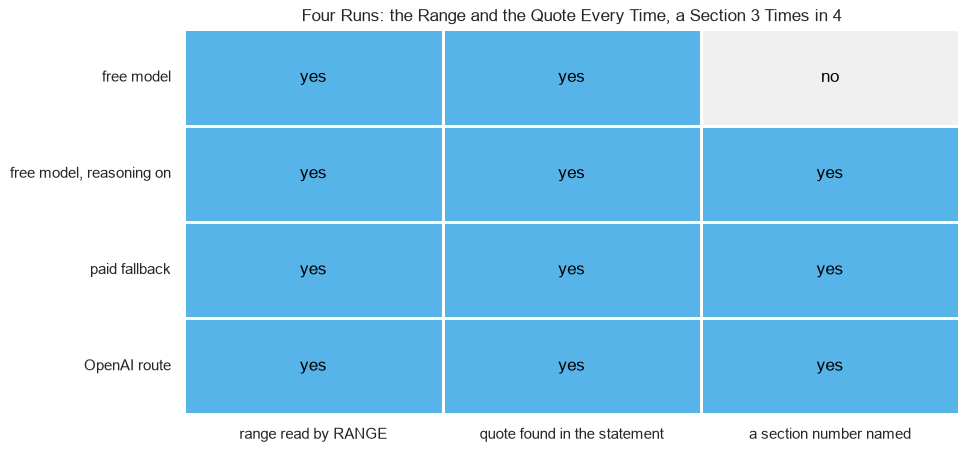

In [43]:
# the four runs by the three checks, yes in blue
sns.heatmap(checks.astype(int), annot=checks.replace({True: "yes", False: "no"}), fmt="", cmap=["#F0F0F0", "#56B4E9"],
            cbar=False, linewidths=1, annot_kws={"color": "black"})
plt.title("Four Runs: the Range and the Quote Every Time, a Section 3 Times in 4")
plt.show()

Every run states the range and quotes the statement word for word.

Three name "Section 1", and a statement has no sections: a reference the checks do not confirm.

## Every Request of the Day

In [44]:
# the 13 requests of the lesson: prompt, returned answer and reasoning tokens, and the cost at the fallback's list price
day_runs = {"first request": response, "max_tokens 20": short, "paid fallback": fallback, "reasoning on": reasoning_on,
            "equity question": paragraph_answers[0], "interest question": paragraph_answers[1], "OpenAI route": openai_response}
for s in six:
    day_runs[f"summary, temperature {s['request']['params']['temperature']}, seed {s['request']['params']['seed']}"] = s
tokens = pd.DataFrame({name: {"prompt": run["usage"]["prompt_tokens"],
                              "answer": run["usage"]["completion_tokens"] - run["usage"]["completion_tokens_details"]["reasoning_tokens"],
                              "reasoning": run["usage"]["completion_tokens_details"]["reasoning_tokens"]} for name, run in day_runs.items()}).T
tokens["cost"] = tokens["prompt"] * float(prompt_price) + (tokens["answer"] + tokens["reasoning"]) * float(completion_price)
print(len(tokens), "requests |", tokens["prompt"].sum(), "prompt and", tokens["answer"].sum() + tokens["reasoning"].sum(),
      f"completion tokens | US${tokens['cost'].sum():.7f} at the fallback's list price")

13 requests | 4064 prompt and 1705 completion tokens | US$0.0010884 at the fallback's list price


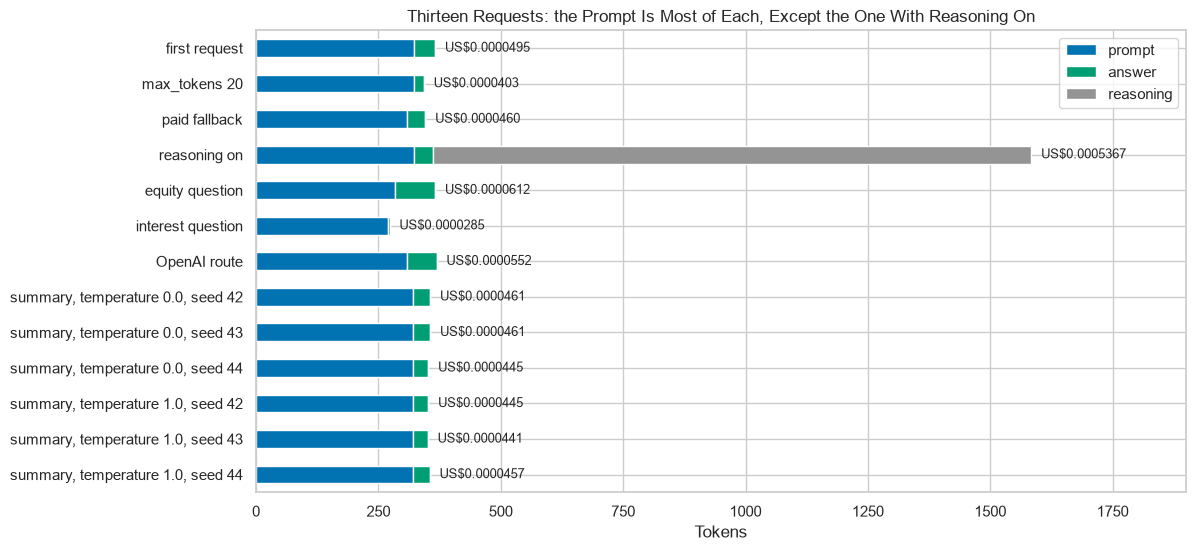

In [45]:
# each request as one bar: prompt, answer and reasoning tokens stacked, its cost at the right
ax = tokens[["prompt", "answer", "reasoning"]].plot.barh(stacked=True, figsize=(12, 6), color=["C0", "C2", "C7"])
for y, (total, cost) in enumerate(zip(tokens[["prompt", "answer", "reasoning"]].sum(axis=1), tokens["cost"])):
    ax.text(total + 20, y, f"US${cost:.7f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="Tokens", xlim=(0, 1900), title="Thirteen Requests: the Prompt Is Most of Each, Except the One With Reasoning On")
plt.show()

At the fallback's list price the 13 requests cost US$0.0010884 in all, about a tenth of a cent; the free model cost nothing.

The one request with reasoning on holds more tokens than any other two together.

**One request shape, three models, two routes; the check is the same every time.**

# Insights and Conclusion

A request is a 509-character system prompt and a 954-character user message, sent with five settings.

Replay finds a response by its request key; two words added change 60 of its 64 characters.

Every run stated the range the statement states; three named a section a statement does not have.

At temperature 0.0 three seeds returned 2 texts; at 1.0, 3.

The provider billed 323 prompt tokens for 239 of Day 1's tokens; reasoning added 1,222 hidden tokens, 10.84 times the price.

The system prompt made NOT IN TEXT a response where the paragraph is silent.

**Write the request, fingerprint it, check the answer against the document, and price it.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Write a request as a system prompt, a user message and five settings.
* Load a key from three places without printing it, and replay saved responses without one.
* Fingerprint a request and read why a changed request has no saved response.
* Check a number in a response against the document with a regular expression.
* Read `usage` and `finish_reason`, and price a request per token.
* Read the HTTP codes a request can meet, and move it to another route.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**An Earlier Statement**

In [47]:
# LLM response
# QUESTION on the statement of 2008-12-16 through ask, then RANGE on the response
earlier = statements[statements["date"] == "2008-12-16"].iloc[0]
ex1_response = ask(f"{QUESTION}\n\nFOMC statement of {earlier['date']}:\n{normalize_text(earlier['text'])}")
ex1_text = normalize_text(ex1_response["content"])
ex1_range = list(re.search(RANGE, ex1_text).groups())
ex1_prompt = ex1_response["usage"]["prompt_tokens"]
print(ex1_text)
print("range:", ex1_range, "| prompt tokens:", ex1_prompt)
llm_line(ex1_response)

The statement says: "The Federal Open Market Committee decided today to establish a target range for the federal funds rate of 0 to 1/4 percent."
range: ['0', '1/4'] | prompt tokens: 650
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


In [48]:
check("Exercise 1 the range in the response", ex1_range, ["0", "1/4"])
check("Exercise 1 the prompt tokens", ex1_prompt, 650)

Exercise 1 the range in the response: correct
Exercise 1 the prompt tokens: correct


### Exercise 2

**A Cost Table**

In [49]:
# one row per response, its cost at the (prompt, completion) prices
def cost_table(responses, prices):
    """One row per response: its model, prompt and completion tokens, and its cost in US$ at prices."""
    rows = []
    for saved in responses:
        prompt_tokens, completion_tokens = saved["usage"]["prompt_tokens"], saved["usage"]["completion_tokens"]
        rows.append({"model": saved["model"], "prompt tokens": prompt_tokens, "completion tokens": completion_tokens,
                     "cost (US$)": prompt_tokens * float(prices[0]) + completion_tokens * float(prices[1])})
    return pd.DataFrame(rows)


# the six summaries at the fallback's list price, and the total as text with 7 decimals
table = cost_table(six, PRICES[FALLBACK_MODEL])
ex2_total = f"{table['cost (US$)'].sum():.7f}"
print(table.drop(columns="model").to_string(index=False, float_format="{:.7f}".format))
print("total: US$" + ex2_total)

 prompt tokens  completion tokens  cost (US$)
           321                 35   0.0000461
           321                 35   0.0000461
           321                 31   0.0000445
           321                 31   0.0000445
           321                 30   0.0000441
           321                 34   0.0000457
total: US$0.0002710


In [50]:
check("Exercise 2 the six summaries at the fallback's price", ex2_total, "0.0002710")

Exercise 2 the six summaries at the fallback's price: correct


### Exercise 3

**A Number in the Text**

In [51]:
# a word boundary before the number, and the number's full stop escaped
def number_in_text(number, text):
    """True when the number appears in the text with a word boundary before it."""
    return re.search(r"\b" + re.escape(number), text) is not None


ex3_found = [number_in_text(number, paragraph) for number in ["40%", "104.750%"]]
ex3_interest = number_in_text("4.750%", paragraph)
print(ex3_found, "| the coupon found:", ex3_interest, "| a plain in test:", "4.750%" in paragraph)

[True, True] | the coupon found: False | a plain in test: True


In [52]:
check("Exercise 3 the two percentages", ex3_found, [True, True])
check("Exercise 3 the coupon in the paragraph", ex3_interest, False)

Exercise 3 the two percentages: correct
Exercise 3 the coupon in the paragraph: correct


### Exercise 4: AI check

**A Helper That Shows Too Much**

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def show_request(messages, model, key):
    """Print what a request will send, for debugging."""
    headers = {"Authorization": f"Bearer {key}", "Content-Type": "application/json"}
    for name, value in headers.items():
        print(name + ": " + value)
    print("model:", model, "| messages:", len(messages))

In [54]:
# the helper's output captured, never shown: redirect_stdout sends its printing into a StringIO,
# getvalue() returns that text, and splitlines() cuts it into lines
captured = io.StringIO()
with contextlib.redirect_stdout(captured):
    show_request(messages, TEXT_MODEL, "sk-or-FAKEFAKEFAKE")
lines = captured.getvalue().splitlines()
print("lines captured:", len(lines), "| lines holding the fake key:", sum("FAKEFAKEFAKE" in line for line in lines))

lines captured: 3 | lines holding the fake key: 1


In [55]:
# the fix: the key goes into the request, never into what the helper prints
def show_request(messages, model, key):
    """Print what a request will send, for debugging, with the key left out."""
    headers = {"Authorization": "Bearer (not shown)", "Content-Type": "application/json"}
    for name, value in headers.items():
        print(name + ": " + value)
    print("model:", model, "| messages:", len(messages))


captured = io.StringIO()
with contextlib.redirect_stdout(captured):
    show_request(messages, TEXT_MODEL, "sk-or-FAKEFAKEFAKE")
ex4_count = sum("FAKEFAKEFAKE" in line for line in captured.getvalue().splitlines())
print("lines holding the fake key:", ex4_count)

lines holding the fake key: 0


In [56]:
check("Exercise 4 the lines holding the key", ex4_count, 0)

Exercise 4 the lines holding the key: correct


## Congratulations!

You wrote your first request to a language model: two messages and five settings, and nothing hidden.
You found its saved response by a fingerprint, checked the range it returned against the statement with code, and priced it to the seventh decimal.
You watched one question come back in five wordings, a cut answer stop at 20 tokens, and 1,222 tokens of reasoning that never came back at all.
You heard NOT IN TEXT where the paragraph was silent, which is exactly what the system prompt asks for.
In Day 12 the model returns JSON to a schema, and every quote and number in it is checked against the indenture.

[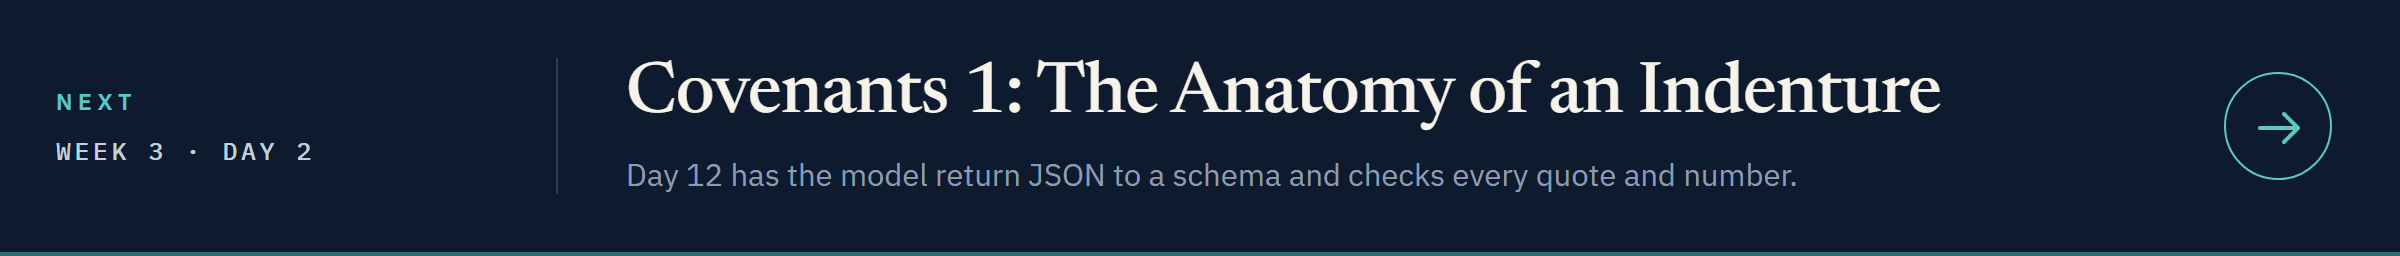](../day2/12_covenants_1_the_anatomy_of_an_indenture.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day2/12_covenants_1_the_anatomy_of_an_indenture.ipynb)